# Guía 5 — Partes IV y V: Movimiento circular, radiación relativista y tiempo del observador

**Electromagnetismo Intermedio · Universidad de Valparaíso · 2026**

Problemas **10–14** de la Guía 5.

| Problema | Simulación | Idea central |
|---|---|---|
| 10 | Órbita circular no relativista; **colapso del átomo clásico** (espiral + *chirp*) | Rapidez constante ≠ sin radiación; la física clásica no explica la estabilidad atómica |
| 11 | $P_\parallel$ vs $P_\perp$ (resumen; versión completa en la Guía 6) | $\gamma^6$ vs $\gamma^4$ |
| 12 | Partícula en $\mathbf{B}$ con **reacción de radiación**: espiral, $\gamma(t)$ exacto; pulsos y armónicos sincrotrón | La energía sale de la energía cinética vía la autofuerza |
| 13 | Razón adelante/atrás $\left(\frac{1+\beta}{1-\beta}\right)^3$ | Asimetría extrema cuando $\beta\to1$ |
| 14 | Flujo en el detector ($\kappa^{-6}$) vs. potencia por tiempo de la fuente ($\kappa^{-5}$): la misma energía | Contar energía en el reloj del detector o en el de la fuente |

**Unidades:** $c=1$ y $q/4\pi\varepsilon_0=1$, salvo donde se den números en SI.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))   # em_utils.py está en la raíz del repositorio
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import animation
from scipy.integrate import solve_ivp

import em_utils as u
u.estilo()
C = u.COLORES

# constantes SI
e, me, mp, c, eps0 = 1.602176634e-19, 9.1093837e-31, 1.67262192e-27, 2.99792458e8, 8.8541878128e-12
a0_bohr, r_e = 5.29177210903e-11, 2.8179403262e-15

---
## Problema 10 — Carga en una órbita circular no relativista

$|\mathbf{a}|=\omega^2b=v^2/b$ aunque $|\mathbf{v}|$ sea constante: **la dirección de $\mathbf{v}$ cambia**, y eso es aceleración. Por Larmor:

$$P=\frac{q^2\omega^4b^2}{6\pi\varepsilon_0c^3}=\frac{q^2v^4}{6\pi\varepsilon_0c^3b^2}.$$

La carga en órbita es exactamente el **dipolo rotante** del Problema 8 con $p_0=qb$. Su patrón instantáneo gira con la carga (ver la animación del cuaderno 02), así que un observador fijo ve una intensidad que cambia en el tiempo, salvo en el eje.

### (d) Sin agente externo, la carga cae: el colapso del átomo clásico

Para el electrón en el hidrógeno, $E=-\frac{k}{2r}$ con $k=\frac{e^2}{4\pi\varepsilon_0}$ y $a=\frac{k}{m_er^2}$. Si la pérdida por vuelta es pequeña (órbita casi circular):

$$\frac{dr}{dt}=-\frac{P}{dE/dr}=-\frac43\frac{r_e^2c}{r^2}\;\Longrightarrow\;r^3(t)=a_0^3-4r_e^2c\,t,\qquad t_{\rm colapso}=\frac{a_0^3}{4r_e^2c}\approx1.6\times10^{-11}\,\text{s}.$$

Es uno de los fracasos más famosos de la física clásica, resuelto por la mecánica cuántica. Integramos la EDO numéricamente en SI y la comparamos con la solución exacta.

*Conexión con relatividad general:* un binario compacto que pierde energía por **ondas gravitacionales** (radiación cuadrupolar, $P\propto r^{-5}$) cae según $r^4\propto t_c-t$. El dipolo electromagnético ($P\propto r^{-4}$) da $r^3\propto t_c-t$. Ambos producen un *chirp*: la frecuencia y la amplitud crecen hasta el final.

t_colapso analítico = 1.5562e-11 s ;  numérico (hasta r = 0.02 a0) = 1.5562e-11 s
máx |r_num - r_an| / a0 = 5.2e-08
vueltas hasta r = 0.02 a0: 2.226e+05;  frecuencia inicial 6.580e+15 Hz -> final 2.376e+18 Hz


[guardado] figuras/P10_colapso_atomo_clasico.png


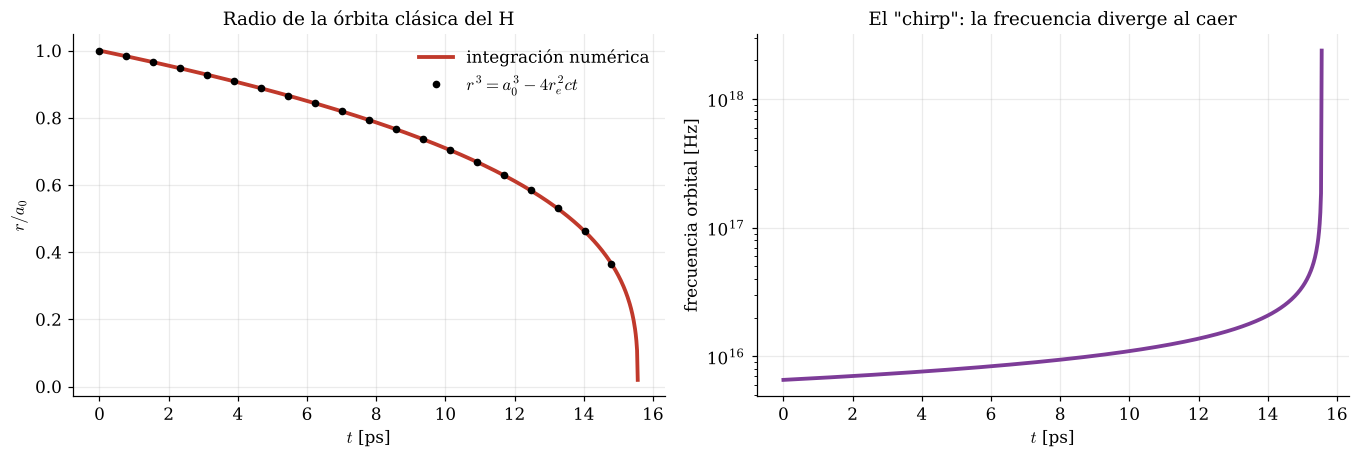

In [2]:
k = e**2/(4*np.pi*eps0)
def drdt(t, r):
    a = k/(me*r[0]**2)
    P = e**2*a**2/(6*np.pi*eps0*c**3)
    return [-P/(k/(2*r[0]**2))]
t_c = a0_bohr**3/(4*r_e**2*c)
ev = lambda t, r: r[0] - 0.02*a0_bohr; ev.terminal = True
sol = solve_ivp(drdt, (0, 2*t_c), [a0_bohr], events=ev, rtol=1e-10, atol=1e-25, dense_output=True)
tt = np.linspace(0, sol.t[-1], 800)
r_num = sol.sol(tt)[0]; r_an = np.cbrt(a0_bohr**3 - 4*r_e**2*c*tt)
f_orb = np.sqrt(k/(me*r_num**3))/(2*np.pi)
N_vueltas = np.trapezoid(f_orb, tt)
print(f"t_colapso analítico = {t_c:.4e} s ;  numérico (hasta r = 0.02 a0) = {sol.t[-1]:.4e} s")
print(f"máx |r_num - r_an| / a0 = {np.abs(r_num - r_an).max()/a0_bohr:.1e}")
print(f"vueltas hasta r = 0.02 a0: {N_vueltas:.3e};  frecuencia inicial {f_orb[0]:.3e} Hz -> final {f_orb[-1]:.3e} Hz")

fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.3))
A = ax[0]
A.plot(tt*1e12, r_num/a0_bohr, color=C['E'], lw=2.5, label='integración numérica')
A.plot(tt[::40]*1e12, r_an[::40]/a0_bohr, 'ko', ms=4, label=r'$r^3=a_0^3-4r_e^2ct$')
A.set_xlabel('$t$ [ps]'); A.set_ylabel('$r/a_0$'); A.set_title('Radio de la órbita clásica del H'); A.legend()
A = ax[1]
A.semilogy(tt*1e12, f_orb, color=C['S'], lw=2.5)
A.set_xlabel('$t$ [ps]'); A.set_ylabel('frecuencia orbital [Hz]'); A.set_title('El "chirp": la frecuencia diverge al caer')
fig.tight_layout(); u.guardar(fig, 'P10_colapso_atomo_clasico'); plt.show()

**Animación (parámetros exagerados).** En unidades adimensionales ($r_0=1$, $\omega=r^{-3/2}$ como en Kepler), $\dot r=-\epsilon/r^2$ con $\epsilon=0.01$, unas 10 vueltas hasta el colapso. A la derecha, el campo que mide un observador lejano sobre el eje $z$: $E_x\propto-a_x(t_r)$.

In [3]:
eps = 0.01
def rhs(t, y):
    r, ph = y
    return [-eps/r**2, r**-1.5]
ev2 = lambda t, y: y[0] - 0.12; ev2.terminal = True
s2 = solve_ivp(rhs, (0, 100), [1.0, 0.0], events=ev2, max_step=0.005, rtol=1e-10, atol=1e-12)
tA, rA, phA = s2.t, s2.y[0], s2.y[1]
xA, yA = rA*np.cos(phA), rA*np.sin(phA)
axA = -(rA**-2)*np.cos(phA)            # a = -k r̂/r²  (componente x)
idx = np.linspace(1, len(tA) - 1, 90).astype(int)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.6), gridspec_kw={'width_ratios': [1, 1.5]})
a1.set_aspect('equal'); a1.set_xlim(-1.1, 1.1); a1.set_ylim(-1.1, 1.1); a1.grid(False)
a1.plot(0, 0, 'o', color='k', ms=8)
l1, = a1.plot([], [], color=C['B'], lw=1); p1, = a1.plot([], [], 'o', color=C['E'], ms=7)
a1.set_title('Electrón clásico (ε exagerado)')
a2.set_xlim(0, tA[-1]); a2.set_ylim(axA.min()*1.05, -axA.min()*1.05)
l2, = a2.plot([], [], color=C['E'], lw=1)
a2.set_xlabel('tiempo del observador (menos $R/c$)'); a2.set_ylabel(r'$E_x\propto-a_x$')
a2.set_title('Señal de radiación: chirp')
fig.tight_layout()
def cuadro(j):
    i = idx[j]
    l1.set_data(xA[:i], yA[:i]); p1.set_data([xA[i]], [yA[i]])
    l2.set_data(tA[:i], -axA[:i])
    return l1, p1, l2
anim = animation.FuncAnimation(fig, cuadro, frames=len(idx))
u.guardar_gif(anim, 'P10_animacion_colapso_chirp', fps=15, dpi=75)
plt.close(fig)
# la animación se muestra en la celda siguiente (figuras/P10_animacion_colapso_chirp.gif)

[guardado] figuras/P10_animacion_colapso_chirp.gif  (0.50 MB)


![animación](figuras/P10_animacion_colapso_chirp.gif)

---
## Problema 11 — Aceleraciones paralela y perpendicular

$$P_\parallel=\frac{q^2\gamma^6a^2}{6\pi\varepsilon_0c^3},\qquad P_\perp=\frac{q^2\gamma^4a^2}{6\pi\varepsilon_0c^3},\qquad\frac{P_\parallel}{P_\perp}=\gamma^2\xrightarrow{\beta\to0}1 .$$

La verificación numérica completa (integrando la distribución angular de Liénard) y el efecto faro están en el Problema 4 de `../Guia_06_Radiacion_Covarianza/01_radiacion.ipynb`. Aquí solo la comprobación rápida:

In [4]:
for b in [0.1, 0.6, 0.9]:
    g = 1/np.sqrt(1 - b**2)
    Pp = u.integrar_esfera(lambda n: u.dPdOmega_lienard(n, [0, 0, b], [0, 0, 1]), nmu=3000)/(4*np.pi)
    Pt = u.integrar_esfera(lambda n: u.dPdOmega_lienard(n, [0, 0, b], [1, 0, 0]), nmu=3000)/(4*np.pi)
    print(f"β={b}:  P_par/(2a²/3) = {Pp/(2/3):9.4f} (γ⁶={g**6:9.4f})   P_perp/(2a²/3) = {Pt/(2/3):8.4f} (γ⁴={g**4:8.4f})   cociente = {Pp/Pt:.4f} (γ²={g**2:.4f})")

β=0.1:  P_par/(2a²/3) =    1.0306 (γ⁶=   1.0306)   P_perp/(2a²/3) =   1.0203 (γ⁴=  1.0203)   cociente = 1.0101 (γ²=1.0101)


β=0.6:  P_par/(2a²/3) =    3.8147 (γ⁶=   3.8147)   P_perp/(2a²/3) =   2.4414 (γ⁴=  2.4414)   cociente = 1.5625 (γ²=1.5625)


β=0.9:  P_par/(2a²/3) =  145.7938 (γ⁶= 145.7938)   P_perp/(2a²/3) =  27.7008 (γ⁴= 27.7008)   cociente = 5.2632 (γ²=5.2632)


---
## Problema 12 — Radiación de una carga en un campo magnético ⋆

De $\frac{d(\gamma m\mathbf{v})}{dt}=q\mathbf{v}\times\mathbf{B}$ con $\gamma$ constante (la fuerza magnética no hace trabajo):

$$a_\perp=\frac{|q|vB_0}{\gamma m},\qquad b=\frac{\gamma mv}{|q|B_0},\qquad
P_\perp=\frac{q^2\gamma^4a_\perp^2}{6\pi\varepsilon_0c^3}=\frac{q^4\gamma^2v^2B_0^2}{6\pi\varepsilon_0c^3m^2}.$$

**La paradoja (d).** $q\mathbf{v}\times\mathbf{B}$ no hace trabajo, pero la partícula radia. La energía sale de la energía **cinética**, a través de la fuerza de reacción de radiación: la fuerza que el propio campo de la carga ejerce sobre ella. Esa fuerza no está en la ecuación de Lorentz con campos externos. En el orden dominante (Landau–Lifshitz) actúa como un frenado,

$$\frac{d\gamma}{dt}=-\frac{P_\perp}{mc^2}=-\tau_q\Omega^2(\gamma^2-1),\qquad\Omega=\frac{qB_0}{m},\;\;\tau_q=\frac{q^2}{6\pi\varepsilon_0mc^3},$$

cuya solución exacta es $\gamma(t)=\coth\!\big(\epsilon\,\Omega t+\operatorname{arccoth}\gamma_0\big)$, con $\epsilon=\tau_q\Omega$. Integramos el movimiento completo con $\frac{d\mathbf{u}}{dt}=\Omega\,\frac{\mathbf{u}}{\gamma}\times\hat{z}-\epsilon\,\Omega\,\gamma\,\mathbf{u}$ (con $\mathbf{u}=\gamma\boldsymbol\beta$). El término de frenado da exactamente $d\gamma/dt=-\epsilon\Omega(\gamma^2-1)$. Exageramos $\epsilon$ para ver la espiral.

máx |γ_num - γ_analítico|/γ = 1.8e-09


[guardado] figuras/P12_espiral_enfriamiento_sincrotron.png


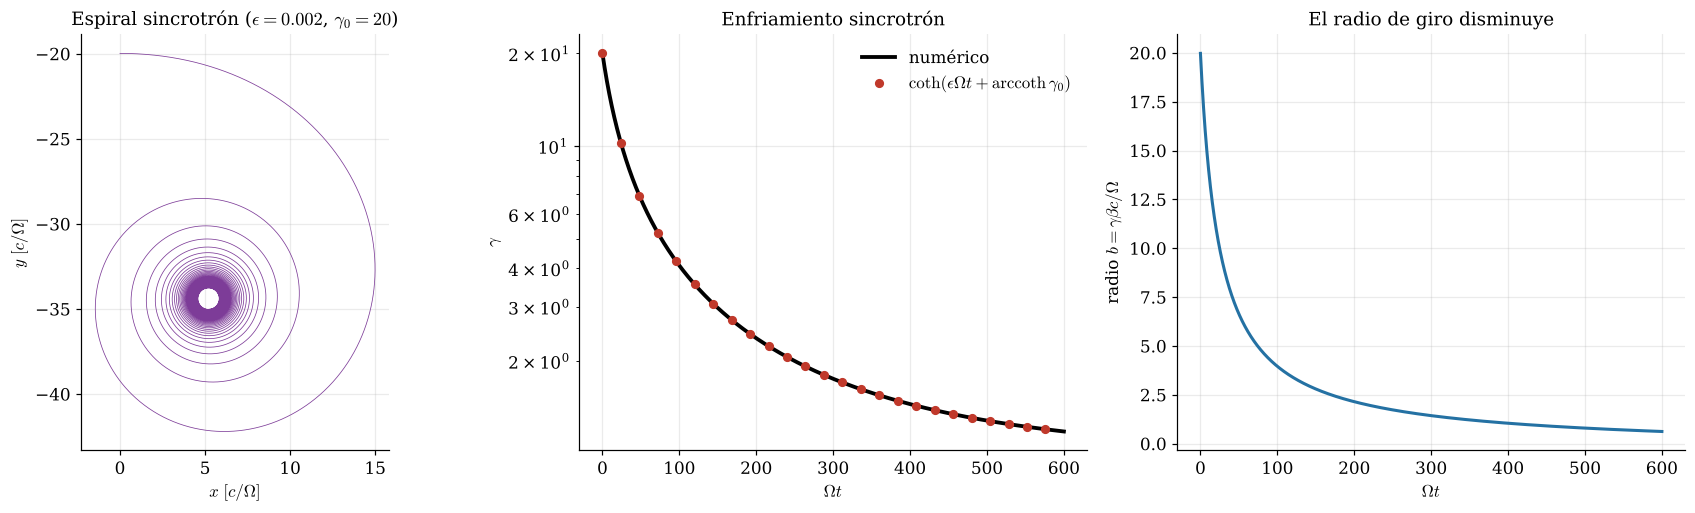


 Partícula   B [T]     γ      t_enfriamiento ≈ 1/(τ_q Ω² γ)
  electrón     1.0      1000      5.159e-03 s
  electrón     8.3      7000      1.070e-05 s
  protón       1.0      1000      3.193e+07 s
  protón       8.3      7000      6.622e+04 s
Los protones radian (m_p/m_e)³ ≈ 6×10⁹ veces menos a igual γ y B (factor q⁴B²/m³): una razón por la que los colisionadores de máxima energía circulares usan protones.


In [5]:
def sincrotron(eps, g0, tmax, n=20000):
    u0 = np.sqrt(g0**2 - 1)
    def f(t, y):
        uvec = y[2:4]; g = np.sqrt(1 + uvec @ uvec)
        du = np.array([uvec[1], -uvec[0]])/g - eps*g*uvec          # (u × ẑ)/γ  - ε γ u   (Ω = 1, q > 0)
        return np.concatenate([uvec/g, du])
    ts = np.linspace(0, tmax, n)
    s = solve_ivp(f, (0, tmax), [0, -u0, u0, 0], t_eval=ts, rtol=1e-10, atol=1e-12, method='DOP853')
    g = np.sqrt(1 + s.y[2]**2 + s.y[3]**2)
    return ts, s.y[0], s.y[1], g

eps, g0 = 0.002, 20.0
ts, xs, ys, gs = sincrotron(eps, g0, 600)
g_an = 1/np.tanh(eps*ts + np.arctanh(1/g0))
print(f"máx |γ_num - γ_analítico|/γ = {np.max(np.abs(gs - g_an)/g_an):.1e}")

fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
A = ax[0]
A.plot(xs, ys, color=C['S'], lw=0.5); A.set_aspect('equal'); A.set_title(f'Espiral sincrotrón ($\\epsilon={eps}$, $\\gamma_0={g0:.0f}$)')
A.set_xlabel(r'$x\;[c/\Omega]$'); A.set_ylabel(r'$y\;[c/\Omega]$')
A = ax[1]
A.semilogy(ts, gs, color='k', lw=2.5, label='numérico')
A.semilogy(ts[::800], g_an[::800], 'o', color=C['E'], ms=5, label=r'$\mathrm{coth}(\epsilon\Omega t+\mathrm{arccoth}\,\gamma_0)$')
A.set_xlabel(r'$\Omega t$'); A.set_ylabel(r'$\gamma$'); A.legend(); A.set_title('Enfriamiento sincrotrón')
A = ax[2]
b_inst = np.sqrt(gs**2 - 1)                       # radio = γβ c/Ω
A.plot(ts, b_inst, color=C['B'], lw=2)
A.set_xlabel(r'$\Omega t$'); A.set_ylabel(r'radio $b=\gamma\beta c/\Omega$'); A.set_title('El radio de giro disminuye')
fig.tight_layout(); u.guardar(fig, 'P12_espiral_enfriamiento_sincrotron'); plt.show()

# números reales: tiempo de enfriamiento ~ 1/(τ_q Ω² γ)
print("\n Partícula   B [T]     γ      t_enfriamiento ≈ 1/(τ_q Ω² γ)")
for nom, m in [('electrón', me), ('protón', mp)]:
    tq = e**2/(6*np.pi*eps0*m*c**3)
    for B, g in [(1.0, 1e3), (8.3, 7.0e3)]:
        Om = e*B/m
        print(f"  {nom:9s}  {B:5.1f}  {g:8.0f}      {1/(tq*Om**2*g):.3e} s")
print("Los protones radian (m_p/m_e)³ ≈ 6×10⁹ veces menos a igual γ y B (factor q⁴B²/m³): una razón por la que los colisionadores de máxima energía circulares usan protones.")

### El observador ve pulsos: espectro de armónicos

Para una carga en órbita circular con $\beta$ dado, un detector lejano **en el plano de la órbita** recibe el campo de radiación de Liénard–Wiechert. Parametrizamos por el tiempo de la fuente: para cada $t_r$ calculamos $t=t_r+|\mathbf{r}-\mathbf{w}(t_r)|/c$ y $\mathbf{E}_{\rm rad}$. Así no hay que resolver la ecuación del retardo. Con $\beta$ pequeño la señal es una sinusoide (solo la frecuencia fundamental). Con $\beta\to1$ es un tren de pulsos de ancho $\sim T/\gamma^3$, cuyo espectro llega a armónicos $n\sim\gamma^3$. Por eso la luz sincrotrón cubre del infrarrojo a los rayos X.

[guardado] figuras/P12_pulsos_y_armonicos_sincrotron.png


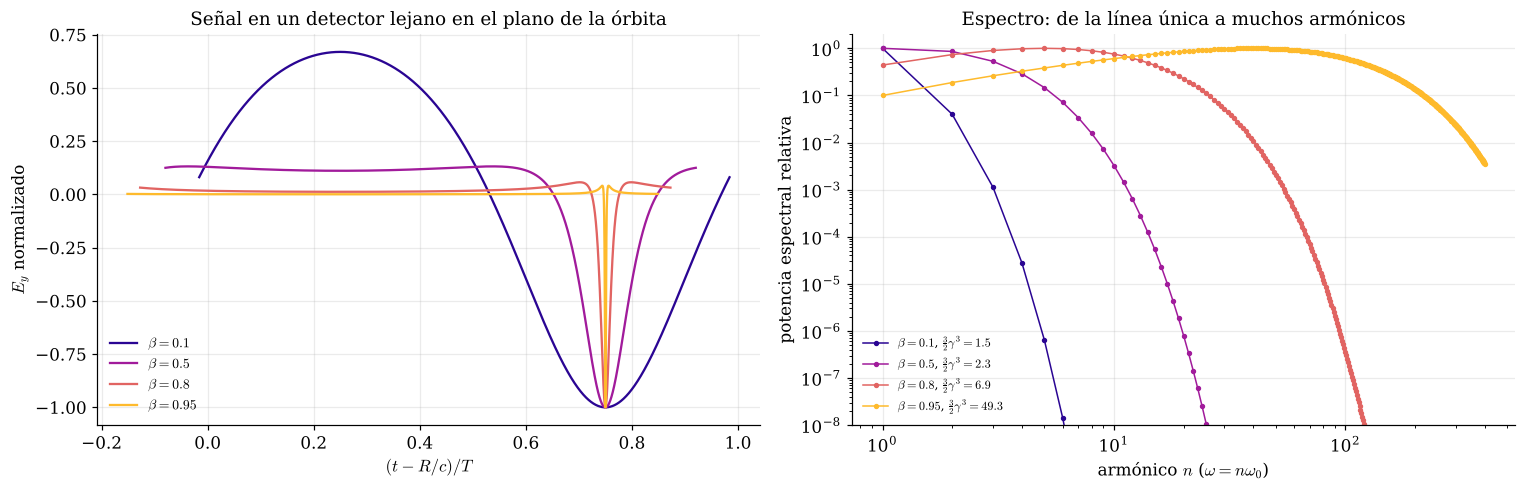

In [6]:
def senal_circular(beta, R=1e5, ntr=2**17, periodos=2):
    # carga en órbita de radio beta (ω = 1, c = 1); detector en +x a distancia R
    tr = np.linspace(0, 2*np.pi*periodos, ntr, endpoint=False)
    w = beta*np.stack([np.cos(tr), np.sin(tr), 0*tr], -1)
    bv = beta*np.stack([-np.sin(tr), np.cos(tr), 0*tr], -1)
    bd = -beta*np.stack([np.cos(tr), np.sin(tr), 0*tr], -1)
    obs = np.array([R, 0, 0])
    Rv = obs - w; Rm = np.linalg.norm(Rv, axis=1); n = Rv/Rm[:, None]
    kap = 1 - np.sum(n*bv, 1)
    E = np.cross(n, np.cross(n - bv, bd))/(kap[:, None]**3*Rm[:, None])
    t_obs = tr + Rm
    return tr, t_obs - R, E, kap, n

fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
for beta, col in zip([0.1, 0.5, 0.8, 0.95], plt.cm.plasma([0.05, 0.35, 0.6, 0.85])):
    tr, t, E, kap, n = senal_circular(beta)
    tu = np.linspace(t[0], t[0] + 2*np.pi, 2**14, endpoint=False)
    Ey = np.interp(tu, t, E[:, 1])
    ax[0].plot(tu/(2*np.pi), Ey/np.abs(Ey).max(), color=col, lw=1.5, label=fr'$\beta={beta}$')
    spec = np.abs(np.fft.rfft(Ey))**2; spec /= spec.max()
    nn = np.arange(len(spec))
    ax[1].loglog(nn[1:400], spec[1:400], 'o-', color=col, ms=2.5, lw=1, label=fr'$\beta={beta}$, $\frac{{3}}{{2}}\gamma^3={1.5/(1-beta**2)**1.5:.1f}$')
ax[0].set_xlabel(r'$(t-R/c)/T$'); ax[0].set_ylabel(r'$E_y$ normalizado'); ax[0].legend(fontsize=9, loc='lower left')
ax[0].set_title('Señal en un detector lejano en el plano de la órbita')
ax[1].set_ylim(1e-8, 2); ax[1].set_xlabel('armónico $n$ ($\\omega=n\\omega_0$)'); ax[1].set_ylabel('potencia espectral relativa')
ax[1].set_title('Espectro: de la línea única a muchos armónicos'); ax[1].legend(fontsize=8)
fig.tight_layout(); u.guardar(fig, 'P12_pulsos_y_armonicos_sincrotron'); plt.show()

---
## Problema 13 — Radiación hacia adelante y hacia atrás ⋆

Con $\boldsymbol\beta\perp\dot{\boldsymbol\beta}$:

- $\hat{n}=+\hat\beta$: $\hat{n}-\boldsymbol\beta=(1-\beta)\hat{n}$ ⇒ $|\hat{n}\times[(\hat{n}-\boldsymbol\beta)\times\dot{\boldsymbol\beta}]|^2=(1-\beta)^2\dot\beta^2$ y $\frac{dP}{d\Omega}\propto\frac{(1-\beta)^2}{(1-\beta)^5}=\frac{1}{(1-\beta)^3}$;
- $\hat{n}=-\hat\beta$: $\frac{dP}{d\Omega}\propto\frac{(1+\beta)^2}{(1+\beta)^5}=\frac1{(1+\beta)^3}$.

$$\frac{(dP/d\Omega)_{\rm adelante}}{(dP/d\Omega)_{\rm atrás}}=\left(\frac{1+\beta}{1-\beta}\right)^3\xrightarrow{\beta=0.6}\left(\frac{1.6}{0.4}\right)^3=64 .$$

β = 0.6:  razón numérica = 64.0   analítica = 64


[guardado] figuras/P13_asimetria_adelante_atras.png


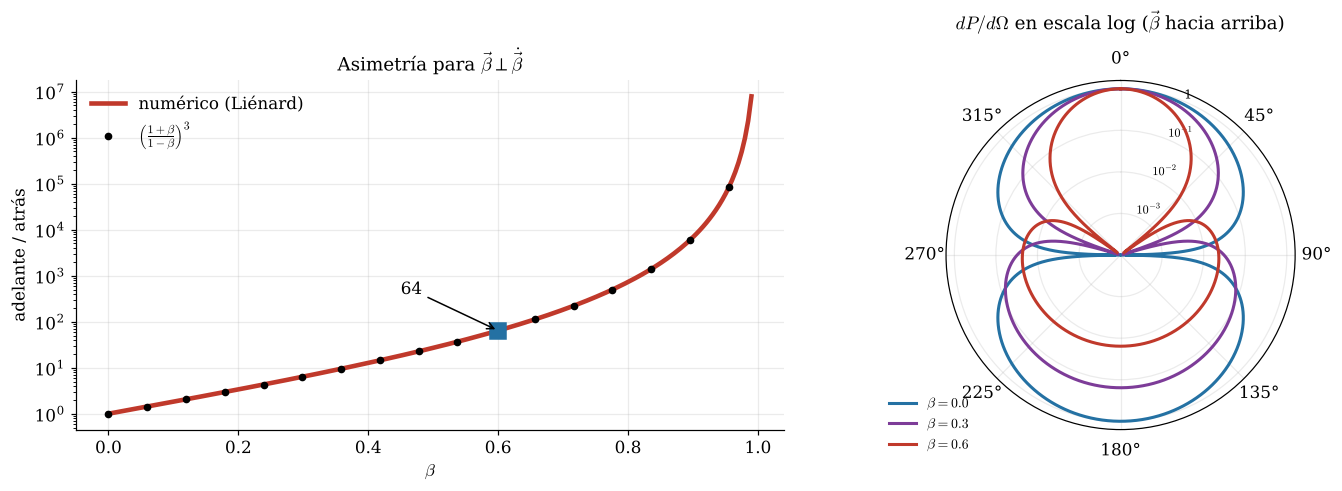

In [7]:
bb = np.linspace(0.0, 0.99, 200)
razon_num = [u.dPdOmega_lienard(np.array([0, 0, 1.0]), [0, 0, b], [1, 0, 0]) /
             u.dPdOmega_lienard(np.array([0, 0, -1.0]), [0, 0, b], [1, 0, 0]) for b in bb]
print("β = 0.6:  razón numérica =", u.dPdOmega_lienard(np.array([0, 0, 1.0]), [0, 0, 0.6], [1, 0, 0]) /
      u.dPdOmega_lienard(np.array([0, 0, -1.0]), [0, 0, 0.6], [1, 0, 0]), "  analítica = 64")
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={'width_ratios': [1.3, 1]})
A = ax[0]
A.semilogy(bb, razon_num, color=C['E'], lw=3, label='numérico (Liénard)')
A.semilogy(bb[::12], ((1 + bb[::12])/(1 - bb[::12]))**3, 'ko', ms=4, label=r'$\left(\frac{1+\beta}{1-\beta}\right)^3$')
A.plot(0.6, 64, 's', color=C['B'], ms=10); A.annotate('64', (0.6, 64), (0.45, 400), arrowprops=dict(arrowstyle='->'))
A.set_xlabel(r'$\beta$'); A.set_ylabel('adelante / atrás'); A.legend(); A.set_title(r'Asimetría para $\vec{\beta}\perp\dot{\vec{\beta}}$')
A = fig.add_subplot(1, 2, 2, projection='polar'); ax[1].remove()
ang = np.linspace(0, 2*np.pi, 2000)
for b, col in zip([0.0, 0.3, 0.6], [C['B'], C['S'], C['E']]):
    n = np.stack([np.sin(ang), 0*ang, np.cos(ang)], -1)
    f = u.dPdOmega_lienard(n, [0, 0, b], [1, 0, 0])
    A.plot(ang, np.log10(f/f.max() + 1e-12) + 4, color=col, lw=2, label=fr'$\beta={b}$')
A.set_theta_zero_location('N'); A.set_theta_direction(-1); A.set_ylim(0, 4.2)
A.set_yticks([1, 2, 3, 4]); A.set_yticklabels(['$10^{-3}$', '$10^{-2}$', '$10^{-1}$', '1'], fontsize=8)
A.set_title('$dP/d\\Omega$ en escala log ($\\vec{\\beta}$ hacia arriba)', pad=14); A.legend(loc='lower left', bbox_to_anchor=(-0.2, -0.1), fontsize=9)
fig.tight_layout(); u.guardar(fig, 'P13_asimetria_adelante_atras'); plt.show()

---
## Problema 14 — Tiempo del observador y tiempo retardado ⋆

De $t=t_r+R(t_r)/c$ y $\frac{dR}{dt_r}=\frac{\mathbf{R}\cdot(-\mathbf{v})}{R}=-c\,\hat{n}\cdot\boldsymbol\beta$:

$$\frac{dt}{dt_r}=1-\hat{n}\cdot\boldsymbol\beta=\kappa .$$

El detector mide energía por unidad de **su** tiempo: $\frac{dW}{dt\,d\Omega}=R^2\mathbf{S}\cdot\hat{n}\propto\frac{|\hat{n}\times[(\hat{n}-\boldsymbol\beta)\times\dot{\boldsymbol\beta}]|^2}{\kappa^6}$. La potencia que **pierde la fuente** se cuenta por unidad de $t_r$:

$$\frac{dP}{d\Omega}=R^2\mathbf{S}\cdot\hat{n}\,\frac{dt}{dt_r}=\kappa\,R^2\mathbf{S}\cdot\hat{n}\;\propto\;\kappa^{-5}.$$

Son la **misma energía** contada con dos relojes: $\int R^2\mathbf{S}\cdot\hat{n}\,dt=\int\frac{dP}{d\Omega}\,dt_r$. Lo verificamos con la carga en órbita circular del Problema 12, para un detector en el plano.

β = 0.02:  máx|dt/dt_r - κ| = 4.8e-07   ∫R²S dt = 1.001301e-04   ∫dP/dΩ dt_r = 1.001301e-04   pico obs/pico fuente = 1.020 (≈ 1/κ_min = 1.020)
β = 0.7:  máx|dt/dt_r - κ| = 4.7e-07   ∫R²S dt = 9.018567e-01   ∫dP/dΩ dt_r = 9.018567e-01   pico obs/pico fuente = 3.333 (≈ 1/κ_min = 3.333)


[guardado] figuras/P14_kappa5_vs_kappa6.png


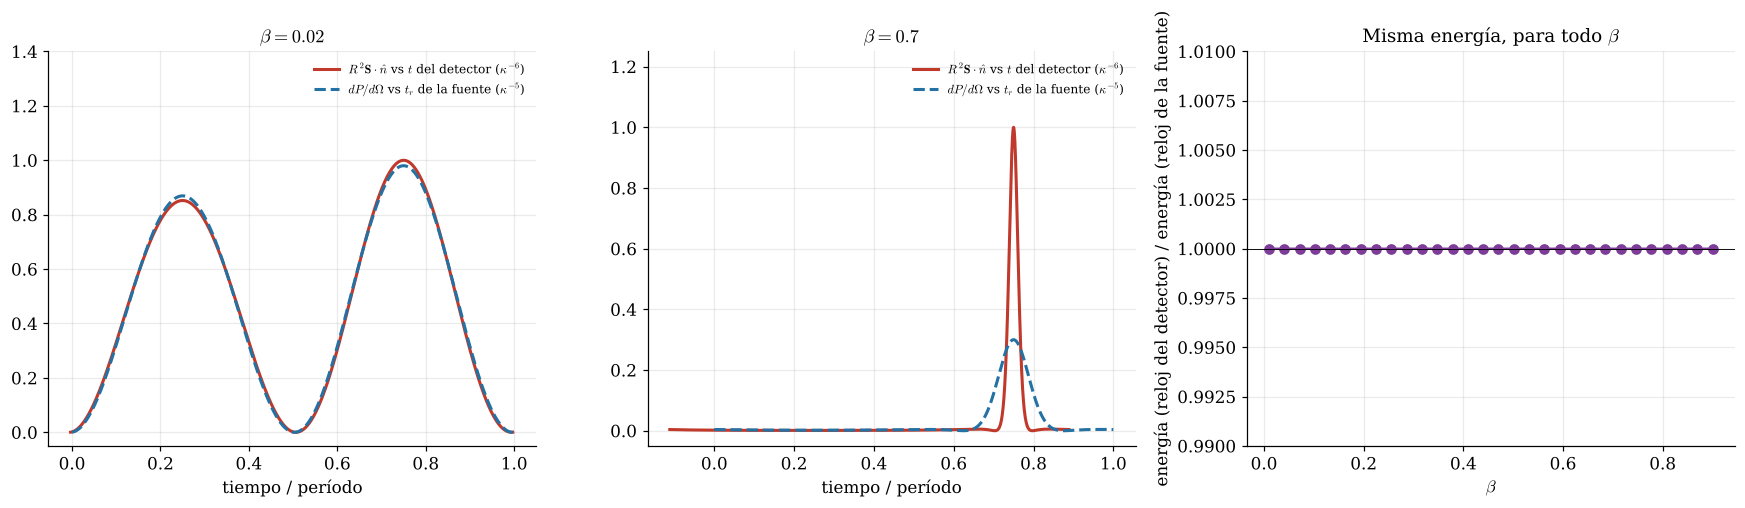

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
for j, beta in enumerate([0.02, 0.7]):
    tr, t, E, kap, n = senal_circular(beta, periodos=1)
    R = 1e5
    flujo_obs = R**2*np.sum(E**2, 1)/(4*np.pi)          # R² S·n  (por unidad de t del observador)
    dPdO = kap*flujo_obs                                 # por unidad de t_r
    # dt/dt_r numérico vs κ
    dtdtr = np.gradient(t, tr)
    W_obs = np.trapezoid(flujo_obs, t); W_src = np.trapezoid(dPdO, tr)
    print(f"β = {beta}:  máx|dt/dt_r - κ| = {np.abs(dtdtr - kap)[2:-2].max():.1e}   "
          f"∫R²S dt = {W_obs:.6e}   ∫dP/dΩ dt_r = {W_src:.6e}   pico obs/pico fuente = {flujo_obs.max()/dPdO.max():.3f} (≈ 1/κ_min = {1/kap.min():.3f})")
    A = ax[j]
    A.plot(t/(2*np.pi), flujo_obs/flujo_obs.max(), color=C['E'], lw=2, label=r'$R^2\mathbf{S}\cdot\hat{n}$ vs $t$ del detector ($\kappa^{-6}$)')
    A.plot(tr/(2*np.pi), dPdO/flujo_obs.max(), color=C['B'], lw=2, ls='--', label=r'$dP/d\Omega$ vs $t_r$ de la fuente ($\kappa^{-5}$)')
    A.set_xlabel('tiempo / período'); A.set_title(fr'$\beta={beta}$'); A.legend(fontsize=8, loc='upper right')
    A.set_ylim(-0.05, 1.25 if beta > 0.1 else 1.4)
A = ax[2]
bs = np.linspace(0.01, 0.9, 30); ratios = []
for b in bs:
    tr, t, E, kap, n = senal_circular(b, periodos=1, ntr=2**15)
    fo = np.sum(E**2, 1)
    ratios.append(np.trapezoid(fo, t)/np.trapezoid(kap*fo, tr))
A.plot(bs, ratios, 'o-', color=C['S'])
A.set_ylim(0.99, 1.01); A.axhline(1, color='k', lw=0.6)
A.set_xlabel(r'$\beta$'); A.set_ylabel('energía (reloj del detector) / energía (reloj de la fuente)')
A.set_title('Misma energía, para todo $\\beta$')
fig.tight_layout(); u.guardar(fig, 'P14_kappa5_vs_kappa6'); plt.show()

**Lectura.** Con $\beta=0.02$ las dos curvas coinciden: $\kappa\approx1$ y el límite no relativista no distingue los relojes (inciso d). Con $\beta=0.7$ el detector ve un pico más **alto y angosto**: la emisión de un intervalo $dt_r$ le llega comprimida en $dt=\kappa\,dt_r$. Por eso tiene un factor $1/\kappa$ adicional en el pico, aunque el área bajo cada curva, la energía total, sea la misma.

Este es el factor que convierte $\kappa^{-5}$ en $\kappa^{-6}$, y es el mismo $dt/dt_r$ del Problema 1.